In [12]:
import random

import os

import warnings
warnings.filterwarnings('ignore')

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score

import lightgbm as lgb

import matplotlib.pyplot as plt
import seaborn as sns
import graphviz


In [13]:
RS = 2000000
FS = 5


In [14]:
seed = 1723

random.seed(seed)
np.random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)


In [15]:
## посмотрим на градиенты и гессианы 

## создадим кастомный лосс, 
## повторяет bce, 
## добавим print 


In [16]:
x, y = make_classification(n_samples=10000, weights=[.80, .20])

nums = [f'feat{i}' for i in range(x.shape[1])]
df = pd.DataFrame(x, columns=nums)

target = 'label'
df[target] = y

train, valid = train_test_split(df)

# mean = train[target].mean()
# bias = np.log(mean/(1-mean))

train_dataset = lgb.Dataset(
    train[nums], 
    label=train[target], 
    # init_score=np.full(len(train), bias)
)
valid_dataset = lgb.Dataset(
    valid[nums], 
    label=valid[target], 
    # init_score=np.full(len(valid), bias)
)


In [17]:
class NewLoss:
    
    def __init__(self):
        self.iteration = 0
        
    def __call__(self, y_pred, d_train):

        if self.iteration == 0:
            print (y_pred[:6])
            print ('\n')

        y = d_train.get_label()
        p = 1.0 / (1.0 + np.exp(-np.clip(y_pred, -250, 250)))
        
        grad = p - y
        hess = p * (1.0 - p)
        
        if self.iteration < 6:
            print (self.iteration, len(grad), len(set(grad)), grad[:5])
            print (self.iteration, len(hess), len(set(hess)), hess[:5])
            print ('\n')

        self.iteration += 1
        
        return grad, hess

def new_metrics(y_pred, d_train):
    
    y = d_train.get_label()
    p = 1.0 / (1.0 + np.exp(-np.clip(y_pred, -250, 250)))
    
    ms = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
    
    return 'logloss', ms, False  

params = {
    'objective': NewLoss(), 
    "max_depth": 5, 
    "verbose": -1 
}
evals_result = {}
model = lgb.train(params, 
                  feval=new_metrics,  
                  num_boost_round=100,   
                  train_set=train_dataset, 
                  valid_sets=[train_dataset, 
                              valid_dataset], 
                  callbacks=[lgb.record_evaluation(evals_result)])


[0. 0. 0. 0. 0. 0.]


0 7500 2 [0.5 0.5 0.5 0.5 0.5]
0 7500 1 [0.25 0.25 0.25 0.25 0.25]




1 7500 51 [0.45103757 0.45028073 0.46776962 0.45028073 0.45028073]
1 7500 26 [0.24760268 0.24752799 0.2489612  0.24752799 0.24752799]


2 7500 118 [0.40674147 0.40673204 0.43800573 0.40669901 0.40600398]
2 7500 73 [0.24130285 0.24130109 0.24615671 0.24129493 0.24116475]


3 7500 174 [0.36761285 0.36691792 0.41212419 0.36688613 0.36621714]
3 7500 107 [0.23247364 0.23228916 0.24227784 0.2322807  0.23210215]


4 7500 328 [0.33207249 0.33140953 0.388102   0.3313792  0.33074113]
4 7500 224 [0.22180035 0.22157725 0.23747884 0.22156703 0.22135144]


5 7500 655 [0.29999792 0.30012323 0.36565039 0.2999339  0.29873764]
5 7500 484 [0.20999917 0.21004928 0.23195018 0.20997355 0.20949346]




In [18]:
## посмотрим на структуру дерева 

## если повезёт с сидом, 
## увидим без симметрии 


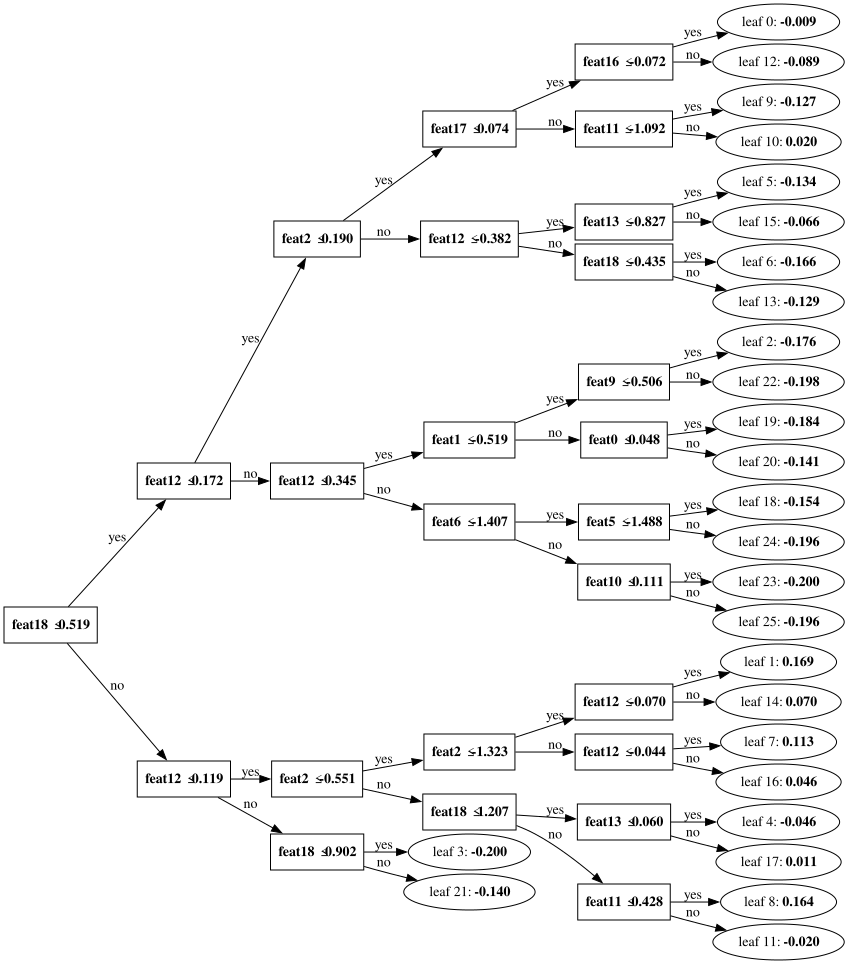

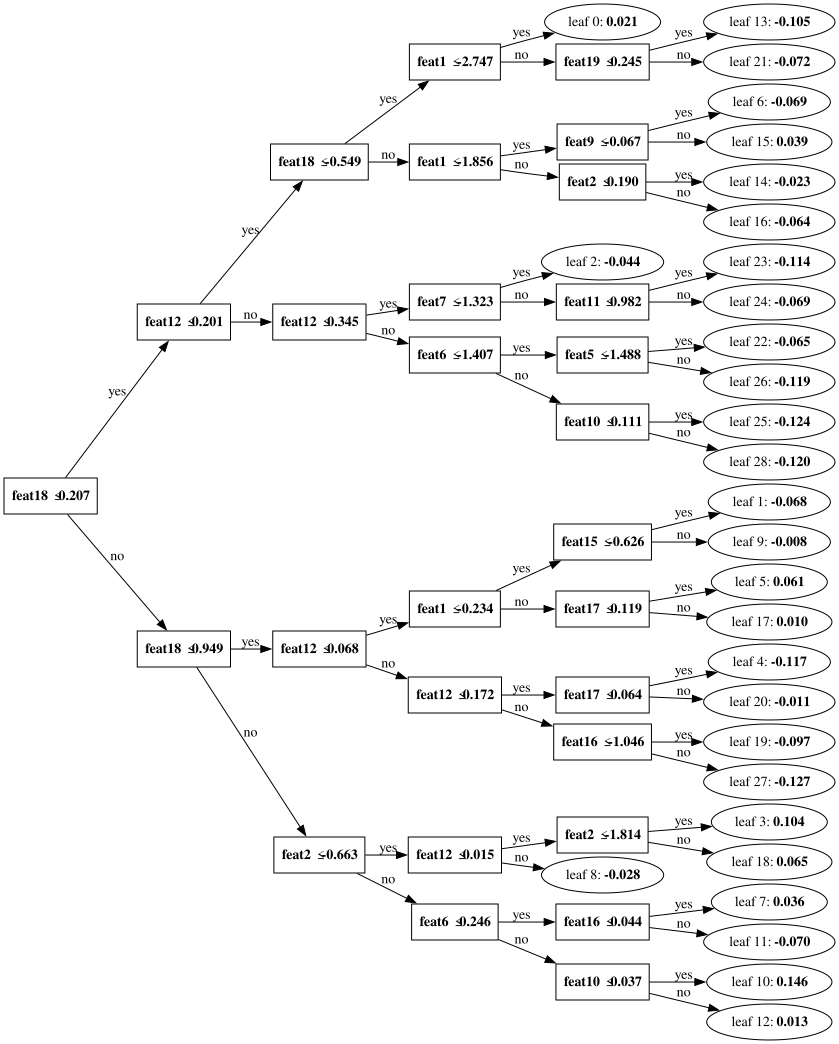

In [19]:
for i in [0, 9]:
    graph_data = lgb.create_tree_digraph(model, 
                                         tree_index=i)
    graph_data.render("tree")
    display(graph_data)


In [20]:
## посмотрим на важность сплита данных 
## понятие overfitting и роль valid  


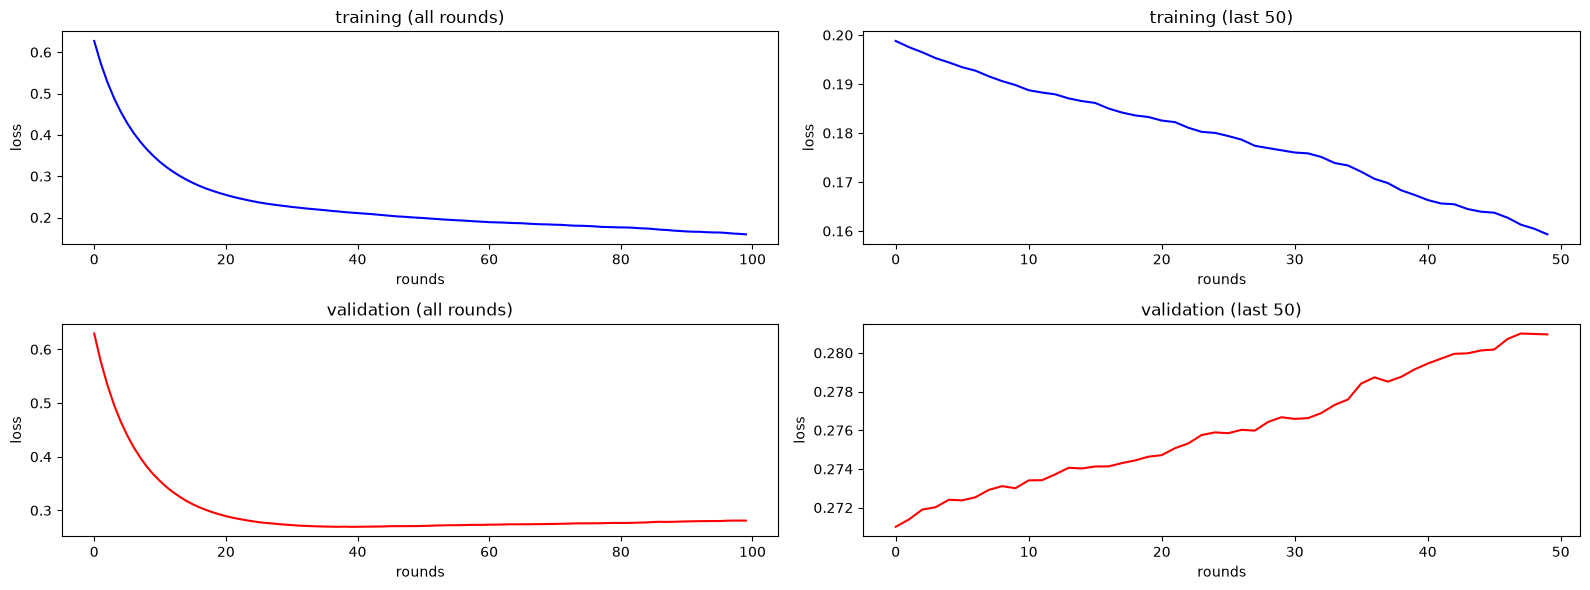

In [21]:
l = [
    (evals_result['training']['logloss'], 'training (all rounds)', 'blue'), 
    (evals_result['training']['logloss'][-50:], 'training (last 50)', 'blue'), 
    
    (evals_result['valid_1']['logloss'], 'validation (all rounds)', 'red'), 
    (evals_result['valid_1']['logloss'][-50:], 'validation (last 50)', 'red')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 6))
axes = axes.flatten()

for i, (data, title, color) in enumerate(l):
    sns.lineplot(data, 
                 color=color, 
                 ax=axes[i])
    axes[i].set_title(title)
    axes[i].set_xlabel('rounds')
    axes[i].set_ylabel('loss')

plt.tight_layout()
plt.show()


In [22]:
## перейдём к кросс-валидации 
## схема out-of-fold 


In [23]:
inds = []
kf = KFold(n_splits=FS, 
           shuffle=True, 
           random_state=1723)
for (train_index, valid_index) in kf.split(df):
    inds += [[train_index, valid_index]]


In [24]:
def training_phase(train, valid, 
                   nums, cats, 
                   target):

    train_dataset = lgb.Dataset(train[nums+cats], 
                                train[target], 
                                categorical_feature=cats)
    valid_dataset = lgb.Dataset(valid[nums+cats], 
                                valid[target], 
                                categorical_feature=cats)
    
    params = {
        "objective": "binary", 
        "boosting_type": "gbdt", 
        "num_boost_rounds": 1000, 
        "early_stopping_round": 100, 
        "max_depth": -1, 
        "bagging_fraction": .5, 
        "features_fraction": .5, 
        "verbose": -1, 
        "nthreads": 4, 
        "random_state": 1723
    }
    model = lgb.train(params=params, 
                      train_set=train_dataset, 
                      valid_sets=valid_dataset)
    
    esti = model.predict(valid[nums+cats])
    ms = roc_auc_score(valid[target], 
                       esti)
    
    return model, ms

metrics = []

for fold in tqdm(range(FS)):
    model, ms = training_phase(df.iloc[inds[fold][0]], 
                               df.iloc[inds[fold][1]], 
                               nums, [], 
                               target)
    
    metrics += [ms]

metrics


ImportError: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html

In [ ]:
## первая задача и роль, аудитория -> microsoft, кибербезопасность 

## познакомимся с алгоритмом адверсальной валидации 
## найдём кандидатов с шифтом 


In [ ]:
def data_collection(p, n=0):
    
    df = pd.read_csv(p)

    if n:
        df = df.sample(n)
        df.reset_index(drop=True, 
                       inplace=True)
    
    start = df.memory_usage().sum() / 1024**2
    
    for c in df.columns:
        t = df[c].dtype
        
        if t != object:
            c_min = df[c].min()
            c_max = df[c].max()
            if str(t)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[c] = df[c].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[c] = df[c].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[c] = df[c].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[c] = df[c].astype(np.int64)  
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[c] = df[c].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[c] = df[c].astype(np.float32)
                else:
                    df[c] = df[c].astype(np.float64)
        else:
            df[c] = df[c].astype('category')

    end = df.memory_usage().sum() / 1024**2

    print('memory usage before optimization is: {:.2f} MB'.format(start))
    print('memory usage after optimization is: {:.2f} MB'.format(end))
    print('decreased by {:.1f}%'.format(100 * (start - end) / start))
    
    return df

df = data_collection("../input/microsoft-malware-prediction/train.csv", RS)

df.head()


memory usage before optimization is: 1266.48 MB
memory usage after optimization is: 370.04 MB
decreased by 70.8%


,MachineIdentifier,ProductName,EngineVersion,AppVersion,AvSigVersion,IsBeta,RtpStateBitfield,IsSxsPassiveMode,DefaultBrowsersIdentifier,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,CityIdentifier,OrganizationIdentifier,GeoNameIdentifier,LocaleEnglishNameIdentifier,Platform,Processor,OsVer,OsBuild,OsSuite,OsPlatformSubRelease,OsBuildLab,SkuEdition,IsProtected,AutoSampleOptIn,PuaMode,SMode,IeVerIdentifier,SmartScreen,Firewall,UacLuaenable,Census_MDC2FormFactor,Census_DeviceFamily,Census_OEMNameIdentifier,Census_OEMModelIdentifier,Census_ProcessorCoreCount,Census_ProcessorManufacturerIdentifier,Census_ProcessorModelIdentifier,Census_ProcessorClass,Census_PrimaryDiskTotalCapacity,Census_PrimaryDiskTypeName,Census_SystemVolumeTotalCapacity,Census_HasOpticalDiskDrive,Census_TotalPhysicalRAM,Census_ChassisTypeName,Census_InternalPrimaryDiagonalDisplaySizeInInches,Census_InternalPrimaryDisplayResolutionHorizontal,Census_InternalPrimaryDisplayResolutionVertical,Census_PowerPlatformRoleName,Census_InternalBatteryType,Census_InternalBatteryNumberOfCharges,Census_OSVersion,Census_OSArchitecture,Census_OSBranch,Census_OSBuildNumber,Census_OSBuildRevision,Census_OSEdition,Census_OSSkuName,Census_OSInstallTypeName,Census_OSInstallLanguageIdentifier,Census_OSUILocaleIdentifier,Census_OSWUAutoUpdateOptionsName,Census_IsPortableOperatingSystem,Census_GenuineStateName,Census_ActivationChannel,Census_IsFlightingInternal,Census_IsFlightsDisabled,Census_FlightRing,Census_ThresholdOptIn,Census_FirmwareManufacturerIdentifier,Census_FirmwareVersionIdentifier,Census_IsSecureBootEnabled,Census_IsWIMBootEnabled,Census_IsVirtualDevice,Census_IsTouchEnabled,Census_IsPenCapable,Census_IsAlwaysOnAlwaysConnectedCapable,Wdft_IsGamer,Wdft_RegionIdentifier,HasDetections
0,2ce98d58aca5d09fd65d7187708625d6,win8defender,1.1.15200.1,4.18.1807.18075,1.275.423.0,0,7.0,0,NaN,53447.0,1.0,1.0,1,205,136125.0,NaN,211.0,182,windows10,x64,10.0.0.0,17134,256,rs4,17134.1.amd64fre.rs4_release.180410-1804,Pro,1.0,0,NaN,0.0,137.0,NaN,1.0,1.0,Desktop,Windows.Desktop,1980.0,317708.0,2.0,1.0,146.0,NaN,476940.0,HDD,102219.0,0,2048.0,Desktop,18.500000,1366.0,768.0,Desktop,NaN,4.294967e+09,10.0.17134.228,amd64,rs4_release,17134,228,Professional,PROFESSIONAL,IBSClean,29.0,125,FullAuto,0,IS_GENUINE,OEM:NONSLP,NaN,0.0,Retail,NaN,142.0,36040.0,0,NaN,0.0,0,0,0.0,0.0,3.0,1
1,7ada5da5538c0f4392a6427dbff7010a,win8defender,1.1.15200.1,4.18.1807.18075,1.275.263.0,0,7.0,0,NaN,53447.0,1.0,1.0,1,207,128469.0,27.0,277.0,75,windows10,x64,10.0.0.0,15063,768,rs2,15063.0.amd64fre.rs2_release.170317-1834,Home,1.0,0,NaN,0.0,108.0,NaN,1.0,1.0,AllInOne,Windows.Desktop,2108.0,258562.0,2.0,5.0,3260.0,NaN,953869.0,HDD,953367.0,0,4096.0,Desktop,20.703125,1680.0,1050.0,Desktop,NaN,4.294967e+09,10.0.15063.1266,amd64,rs2_release,15063,1266,Core,CORE,IBSClean,8.0,31,UNKNOWN,0,IS_GENUINE,Retail,NaN,0.0,Retail,NaN,142.0,12423.0,0,NaN,0.0,1,0,0.0,1.0,13.0,1
2,4dd307418872923100026547eca8bf27,win8defender,1.1.15200.1,4.18.1807.18075,1.275.710.0,0,7.0,0,NaN,53447.0,1.0,1.0,1,142,110910.0,27.0,277.0,75,windows10,x64,10.0.0.0,17134,768,rs4,17134.1.amd64fre.rs4_release.180410-1804,Home,1.0,0,NaN,0.0,137.0,NaN,1.0,1.0,Notebook,Windows.Desktop,2668.0,171404.0,8.0,5.0,3082.0,NaN,953869.0,HDD,952592.0,0,8192.0,Notebook,15.500000,1920.0,1080.0,Mobile,NaN,0.000000e+00,10.0.17134.81,amd64,rs4_release,17134,81,CoreSingleLanguage,CORE_SINGLELANGUAGE,UUPUpgrade,8.0,31,Notify,0,IS_GENUINE,Retail,NaN,0.0,Unknown,NaN,628.0,12176.0,0,NaN,0.0,0,0,0.0,0.0,1.0,0
3,b8ec2e14259f82bb1f2db0102a8797ac,win8defender,1.1.15100.1,4.18.1807.18075,1.273.989.0,0,7.0,0,NaN,53447.0,1.0,1.0,1,164,153323.0,27.0,205.0,172,windows10,x64,10.0.0.0,17134,768,rs4,17134.1.amd64fre.rs4_release.180410-1804,Home,1.0,0,NaN,0.0,137.0,RequireAdmin,1.0,1.0,AllInOne,Windows.Desktop,585.0,190179.0,4.0,5.0,3388.0,NaN,953869.0,HDD,468164.0,0,4096.0,AllinOne,20.000000,1600.0,900.0,Desktop,NaN,4.294967e+09,10.0.17134.112,amd64,rs4_

In [ ]:
test = data_collection("../input/microsoft-malware-prediction/test.csv")

te = test.sample(RS)
te.reset_index(drop=True, 
               inplace=True)


memory usage before optimization is: 4913.08 MB
memory usage after optimization is: 1449.21 MB
decreased by 70.5%


In [ ]:
target = "HasDetections"
nums = [
    "Census_ProcessorCoreCount", 
    "Census_PrimaryDiskTotalCapacity", 
    "Census_SystemVolumeTotalCapacity", 
    "Census_TotalPhysicalRAM", 
    "Census_InternalPrimaryDisplayResolutionHorizontal", 
    "Census_InternalPrimaryDisplayResolutionVertical", 
    "Census_InternalPrimaryDiagonalDisplaySizeInInches", 
    "Census_InternalBatteryNumberOfCharges"
]
cats = [
    c for c in df.columns if c not in nums + [target, "MachineIdentifier"]
]

for c in tqdm(cats):

    df[c] = df[c].astype(str)
    te[c] = te[c].astype(str)

sc = {}
for c in tqdm(cats):
    
    label, uni = pd.factorize(df[c])
    sc[c] = uni
    
    df[c] = sc[c].get_indexer(df[c])
    te[c] = sc[c].get_indexer(te[c])


  0%|          | 0/73 [00:00<?, ?it/s]

  0%|          | 0/73 [00:00<?, ?it/s]

In [ ]:
df["av"] = 0
te["av"] = 1

fr = pd.concat([df, te], 
               axis=0)
fr.reset_index(drop=True, 
               inplace=True)

train, valid = train_test_split(fr, 
                                test_size=.20, 
                                random_state=1723)
train.reset_index(drop=True, 
                  inplace=True)
valid.reset_index(drop=True, 
                  inplace=True)

cs = {}
tr = 1

while tr:
    
    n = [
        c for c in nums if c not in cs
    ]
    c = [
        c for c in cats if c not in cs
    ]
    
    model, metrics = training_phase(train, valid, 
                                    n, c, 
                                    "av")
    
    if metrics > .63:
        
        ind = np.argmax(model.feature_importance("gain"))
        feats_space = n+c
        
        print (feats_space[ind], 
               metrics)
        
        cs[feats_space[ind]] = metrics
    
    else:
        tr = 0

df.drop("av", 
        axis=1, 
        inplace=True)


EngineVersion 0.9800558296592515
SMode 0.973997736743394
AppVersion 0.9741615022837895
AvSigVersion 0.9742027484463948
Census_OSBuildRevision 0.8520958630631355
Census_OSVersion 0.8522576377649702
OsBuildLab 0.6870652274089346
Census_OSBuildNumber 0.6732440607873851
OsBuild 0.6736052827580052
IeVerIdentifier 0.6731185041704758
Census_OSBranch 0.6684171576870033
OsPlatformSubRelease 0.6573563882114692
Census_OSInstallTypeName 0.6470576793482874
Census_OSWUAutoUpdateOptionsName 0.6383419759724389


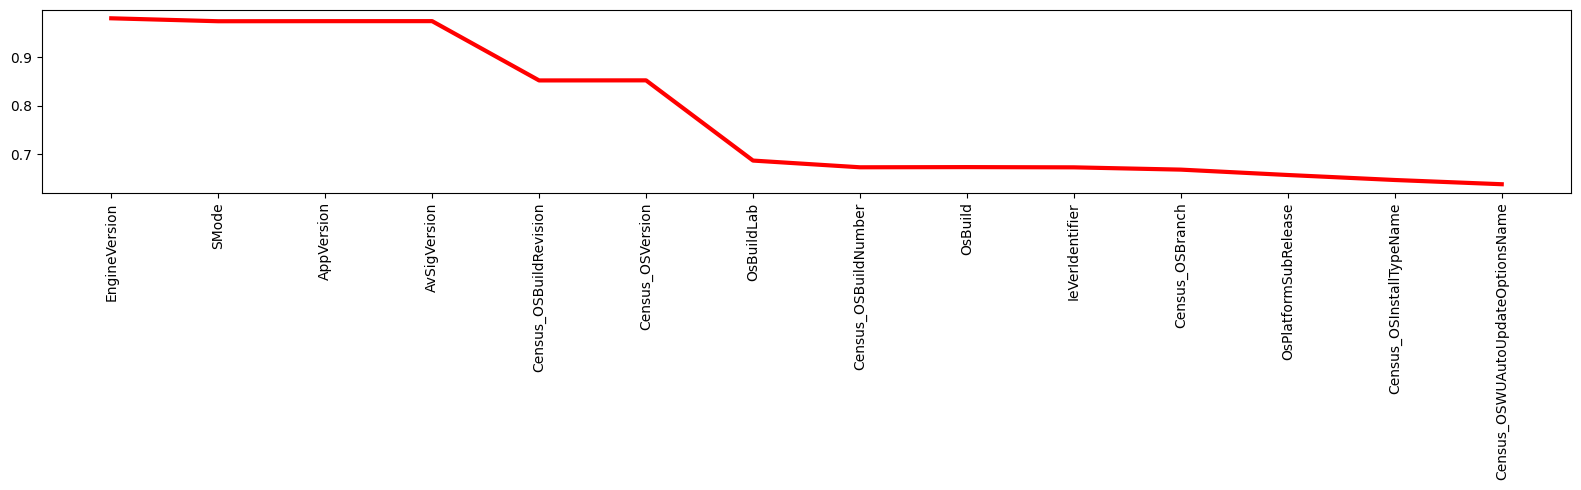

In [ ]:
fr = pd.DataFrame(list(cs.items()), columns=['feats_space', 'roc_auc'])

plt.figure(figsize=(16, 5))

plt.plot(fr['feats_space'], 
         fr['roc_auc'], 
         linewidth=3, 
         color='red')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


In [ ]:
def cats_exploration(df, cs):
    
    df = df[[cs, 'MachineIdentifier']].groupby(cs).count().reset_index()
    df.columns = [cs, 'statistics']
    
    df['statistics'] /= df['statistics'].sum()
    df.sort_values('statistics', 
                   ascending=False, 
                   inplace=True)
    df.reset_index(drop=True, 
                   inplace=True)

    print (df.head())
    print ('\n')

for i in range(3):
    
    cats_exploration(df, fr['feats_space'][i])
    cats_exploration(te, fr['feats_space'][i])


   EngineVersion  statistics
0              0    0.430827
1              1    0.412216
2              7    0.029763
3              9    0.023883
4              8    0.017931


   EngineVersion  statistics
0             -1    0.460424
1              6    0.395026
2              0    0.046772
3              1    0.020189
4              8    0.017808


   SMode  statistics
0      0    0.939488
1      1    0.060062
2      2    0.000450


   SMode  statistics
0      1    0.741878
1      0    0.257306
2      2    0.000816


   AppVersion  statistics
0           0    0.575410
1           9    0.095380
2           8    0.040240
3           1    0.030513
4           5    0.028963


   AppVersion  statistics
0          30    0.348799
1          -1    0.293317
2           0    0.087105
3           8    0.034000
4           5    0.029472




In [ ]:
## попробуйте обучить модель (функция training_phase) 
## посчитать метрики фолдов (метрика roc_auc) 
## собрать submission.csv (cv vs private lb) 

## попробуйте искл признаки из кандидатов в шифты 

## все мешают прогрессу на приватном лидерборде?  

## (домашнее задание) 


In [ ]:
## попробуйте полечить признаки из кандидатов (лечение вместо искл) 
## создайте категории для редких значений (df и test) 

## сохранение части сигнала помогает на приватном лидерборде?  

## (домашнее задание) 


In [ ]:
## подсказка для задания, скелет 


In [ ]:
inds = []
kf = KFold(n_splits=FS, 
           shuffle=True, 
           random_state=1723)
for (train_index, valid_index) in kf.split(df):
    inds += [[train_index, valid_index]]


In [ ]:
for c in tqdm(cats):
    test[c] = test[c].astype(str)
    test[c] = sc[c].get_indexer(test[c])


  0%|          | 0/73 [00:00<?, ?it/s]

In [ ]:
metrics = []

for fold in tqdm(range(FS)):
    
    train = df.iloc[inds[fold][0]]
    train.reset_index(drop=True, 
                      inplace=True)
    
    valid = df.iloc[inds[fold][1]]
    valid.reset_index(drop=True, 
                      inplace=True)
    
    model, ms = training_phase(train, valid, 
                               nums, cats, 
                               target)

    if fold == 0:
        test[target] = model.predict(test[nums+cats])
    else:
        test[target] += model.predict(test[nums+cats])

    metrics += [ms]

print (
    [np.round(ms, 6) for ms in metrics], 
    np.mean(metrics)
)

submission = test[['MachineIdentifier', target]].copy()
submission.to_csv('submission.csv', 
                  index=False)

submission.head()


  0%|          | 0/5 [00:00<?, ?it/s]

[0.717081, 0.720787, 0.718407, 0.718301, 0.719969] 0.7189088598409612


,MachineIdentifier,HasDetections
0,0000010489e3af074adeac69c53e555e,2.676901
1,00000176ac758d54827acd545b6315a5,3.226866
2,0000019dcefc128c2d4387c1273dae1d,2.036128
3,0000055553dc51b1295785415f1a224d,1.470297
4,00000574cefffeca83ec8adf9285b2bf,2.393582


In [ ]:
## вторая задача и роль, аудитория -> home credit, риски 

## посмотрим на важность признаков 
## чувствительность к запуску  


In [ ]:
df = data_collection('../input/competitions/home-credit-default-risk/application_train.csv')

df.head()


memory usage before optimization is: 286.23 MB
memory usage after optimization is: 59.54 MB
decreased by 79.2%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018799,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083008,0.262939,0.139404,0.024704,0.036896,0.972168,0.619141,0.014297,0.000000,0.068970,0.083313,0.125000,0.036896,0.020203,0.018997,0.000000,0.000000,0.025208,0.038300,0.972168,0.634277,0.014397,0.000000,0.068970,0.083313,0.125000,0.037689,0.022003,0.019806,0.0,0.0,0.024994,0.036896,0.972168,0.624512,0.014397,0.000000,0.068970,0.083313,0.125000,0.037506,0.020493,0.019302,0.000000,0.000000,reg oper account,block of flats,0.014900,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003542,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311279,0.622070,NaN,0.095886,0.052887,0.984863,0.795898,0.060486,0.080017,0.034485,0.291748,0.333252,0.013000,0.077271,0.054901,0.003901,0.009804,0.092407,0.053802,0.984863,0.804199,0.049713,0.080627,0.034485,0.291748,0.333252,0.012802,0.078979,0.055389,0.0,0.0,0.096802,0.052887,0.984863,0.798828,0.060791,0.080017,0.034485,0.291748,0.333252,0.013199,0.078674,0.055786,0.003901,0.010002,reg oper account,block of flats,0.071411,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010033,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,

In [ ]:
inds = []
kf = KFold(n_splits=FS, 
           shuffle=True, 
           random_state=1723)
for (train_index, valid_index) in kf.split(df):
    inds += [[train_index, valid_index]]


In [ ]:
target = ['TARGET']
cats = [
    c for c in df.columns if df[c].dtype == 'category'
]
nums = [
    c for c in df.columns if c not in cats + target + ['SK_ID_CURR']
]

sc = {}
for c in tqdm(cats):
    
    label, uni = pd.factorize(df[c])
    sc[c] = uni

    df[c] = sc[c].get_indexer(df[c])


  0%|          | 0/16 [00:00<?, ?it/s]

In [ ]:
splits, gains = [], []
metrics = []

for fold in tqdm(range(FS)):
    model, ms = training_phase(df.iloc[inds[fold][0]], 
                               df.iloc[inds[fold][1]], 
                               nums, cats, 
                               target)
    
    splits += [list(model.feature_importance(importance_type='split'))]
    gains += [list(model.feature_importance(importance_type='gain'))]

    metrics += [ms]

metrics


  0%|          | 0/5 [00:00<?, ?it/s]

[0.7579752703864325,
 0.7491866538381573,
 0.7564341648869619,
 0.7533026716192885,
 0.760752038003621]

In [ ]:
splits = pd.DataFrame(data=splits, columns=nums+cats)

splits


,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,TOTALAREA_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
0,1,47,140,139,109,48,136,93,70,103,76,0,0,18,0,3,0,4,3,23,28,0,0,2,12,1,0,223,191,228,14,16,17,13,10,6,11,15,13,26,11,14,9,11,15,15,12,8,9,3,7,6,8,9,8,18,5,12,5,9,14,4,10,0,3,1,0,6,9,4,1,8,21,14,16,13,22,49,0,19,0,3,0,0,2,0,0,0,0,4,2,0,7,0,7,0,0,0,2,4,3,7,27,31,29,38,2,4,2,11,22,24,13,64,14,423,0,1,6,1
1,4,45,128,95,82,31,126,94,58,83,64,0,0,15,1,9,0,7,4,17,18,0,1,0,12,1,1,229,186,205,13,10,10,10,12,4,10,5,6,13,6,10,2,16,17,12,18,4,11,4,5,2,6,7,7,14,4,7,4,5,6,1,5,1,1,2,2,5,8,5,2,3,20,17,24,10,14,47,0,16,0,1,0,0,1,0,0,0,0,3,2,0,10,0,4,0,0,0,1,1,5,9,14,29,24,41,0,5,4,8,29,26,10,62,15,400,0,0,6,1
2,5,40,132,121,107,38,133,85,65,91,72,0,0,14,0,0,1,11,4,25,21,1,0,4,9,1,6,229,165,201,9,11,20,6,7,4,16,12,6,13,13,17,5,7,15,13,16,4,3,0,11,2,6,13,5,12,12,9,7,0,20,6,2,0,3,6,2,2,8,10,0,2,15,13,23,9,13,59,0,21,0,1,1,0,2,0,0,0,0,2,1,0,8,0,8,0,0,0,0,4,6,2,19,42,23,37,0,4,6,6,24,29,7,76,13,446,2,3,8,1
3,4,59,128,103,100,38,131,89,57,102,70,0,0,16,0,3,0,13,3,18,13,1,0,0,13,0,2,243,179,197,13,11,15,15,10,2,6,12,7,20,12,8,6,10,13,6,15,8,7,1,2,0,4,12,12,14,5,15,4,3,11,2,5,2,9,4,2,3,4,6,2,10,29,15,22,6,15,61,0,14,0,1,0,0,1,0,0,2,0,3,0,0,6,0,6,0,0,0,2,1,3,8,24,35,25,32,1,7,4,6,27,22,9,63,16,405,2,1,4,2
4,5,48,133,98,110,39,122,86,51,84,59,0,0,16,0,4,0,6,2,19,16,1,1,0,13,3,1,215,171,191,16,10,14,10,8,5,10,9,2,7,14,9,7,5,15,10,4,4,2,2,3,3,3,8,11,12,9,9,6,6,13,1,4,3,4,3,1,4,4,6,0,5,15,13,24,8,17,52,0,22,0,1,1,0,0,1,0,1,0,6,0,0,9,0,7,0,0,0,3,2,3,4,26,30,21,30,4,2,2,7,32,22,4,63,12,416,0,0,4,1


In [ ]:
for c in splits.columns:
    if np.max(splits[c]) == 0:
        print (c)


FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_DOCUMENT_2
FLAG_DOCUMENT_4
FLAG_DOCUMENT_7
FLAG_DOCUMENT_10
FLAG_DOCUMENT_12
FLAG_DOCUMENT_15
FLAG_DOCUMENT_17
FLAG_DOCUMENT_19
FLAG_DOCUMENT_20
FLAG_DOCUMENT_21


In [ ]:
splits = splits.rank(axis=1, 
                     method='min', 
                     ascending=False)

for c in splits.columns:
    if np.mean(splits[c]) <= 6:
        print (c, list(splits[c]))


AMT_CREDIT [5.0, 5.0, 6.0, 6.0, 5.0]
DAYS_BIRTH [7.0, 6.0, 5.0, 5.0, 6.0]
EXT_SOURCE_1 [3.0, 2.0, 2.0, 2.0, 2.0]
EXT_SOURCE_2 [4.0, 4.0, 4.0, 4.0, 4.0]
EXT_SOURCE_3 [2.0, 3.0, 3.0, 3.0, 3.0]
ORGANIZATION_TYPE [1.0, 1.0, 1.0, 1.0, 1.0]


In [ ]:
gains = pd.DataFrame(data=gains, columns=nums+cats)

gains


,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,TOTALAREA_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
0,18.881001,684.144877,3670.087259,3659.405714,3581.504939,709.137340,3824.553882,2633.815464,1130.129792,1852.206232,2155.795913,0.0,0.0,326.300241,0.0000,42.852600,0.0000,71.722101,41.677969,627.626688,413.257926,0.0000,0.0000,26.33440,348.029645,16.480200,0.000000,9949.570332,27166.302367,32449.695775,247.834152,237.264340,345.049218,216.300059,159.557701,127.400887,204.344972,375.408459,182.633700,425.018859,215.267970,331.232110,144.883801,192.030371,233.481730,243.765960,181.490981,117.102221,122.286979,40.4601,94.28878,166.361066,111.656001,135.609270,115.572590,306.021273,98.450600,165.982898,69.588738,196.874760,216.517899,67.364999,173.270599,0.000000,46.682001,7.995250,0.000000,82.462930,152.106319,71.185899,17.791500,168.336678,368.432010,182.907300,445.262793,189.898949,535.916801,935.990348,0.0,889.689337,0.0,48.20210,0.0000,0.0,25.770939,0.0000,0.0,0.00000,0.0,36.902211,13.997149,0.0,93.659842,0.0,104.718060,0.0,0.0,0.0,36.317300,74.380400,36.991151,90.544170,474.049955,502.185720,781.426430,1800.880138,29.624700,40.660660,23.330730,326.613110,1820.899445,630.848501,207.131011,2679.581776,177.977150,9554.810511,0.00000,12.447900,102.110002,9.47407
1,61.122701,695.399930,4265.837661,2726.378558,3145.002197,501.260119,3453.394683,2763.960499,1042.529562,1651.170405,2049.591413,0.0,0.0,245.341308,13.6469,115.749529,0.0000,98.080638,138.544899,437.983779,274.823309,0.0000,19.2423,0.00000,256.260022,16.565001,10.325100,9921.745641,27811.330390,32995.530669,244.943597,145.741398,146.319489,204.912500,214.453141,77.261800,163.967502,93.447998,94.631199,193.387259,120.755399,225.370351,21.556800,253.274398,320.736744,201.780997,284.885100,51.960661,194.072001,50.2521,95.28960,35.300500,99.612900,116.118699,109.773201,233.134602,83.249701,121.302102,165.925704,81.055100,171.33959

In [ ]:
for c in gains.columns:
    if np.max(gains[c]) == 0:
        print (c)


FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_DOCUMENT_2
FLAG_DOCUMENT_4
FLAG_DOCUMENT_7
FLAG_DOCUMENT_10
FLAG_DOCUMENT_12
FLAG_DOCUMENT_15
FLAG_DOCUMENT_17
FLAG_DOCUMENT_19
FLAG_DOCUMENT_20
FLAG_DOCUMENT_21


In [ ]:
gains = gains.rank(axis=1, 
                   method='min', 
                   ascending=False)

for c in gains.columns:
    if np.mean(gains[c]) <= 6:
        print (c, list(gains[c]))


AMT_CREDIT [6.0, 5.0, 5.0, 6.0, 5.0]
DAYS_BIRTH [5.0, 6.0, 6.0, 5.0, 7.0]
EXT_SOURCE_1 [3.0, 3.0, 4.0, 4.0, 4.0]
EXT_SOURCE_2 [2.0, 2.0, 2.0, 2.0, 2.0]
EXT_SOURCE_3 [1.0, 1.0, 1.0, 1.0, 1.0]
ORGANIZATION_TYPE [4.0, 4.0, 3.0, 3.0, 3.0]


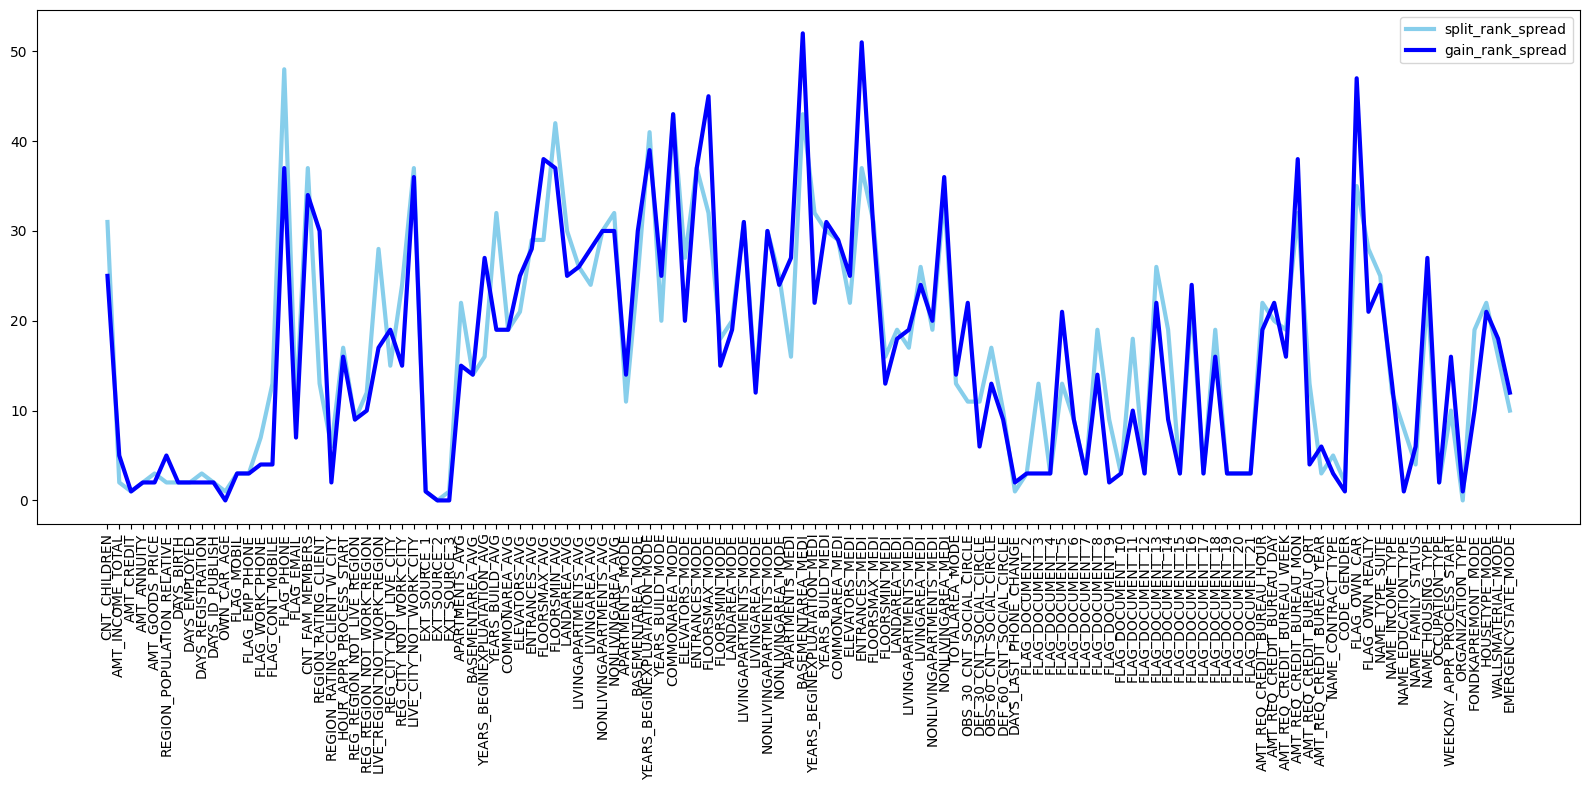

In [ ]:
splits = splits.max() - splits.min()
gains = gains.max() - gains.min()

fr = pd.DataFrame({
    'feats_space': nums+cats,
    'split_rank_spread': splits.values,
    'gain_rank_spread': gains.values
}).set_index('feats_space')

plt.figure(figsize=(16, 8))

for m, c in zip(
    ['split', 'gain'], 
    ['skyblue', 'blue']
):
    plt.plot(fr.index, fr[f'{m}_rank_spread'], 
             label=f'{m}_rank_spread', 
             linewidth=3, 
             color=c)

plt.xticks(rotation=90)

plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
## попробуйте добавить в пространство признаков новые переменные (схема данных) 
## поработать с источниками (снапшоты, поведенческие данные) 

## аплифт в результате features engineering? 

## (домашнее задание) 
